# Preprocessing: train/test split design

This notebook fixes **how basins and years are split** between training and testing, before any scaling, PCA, clustering or model fitting happens. Everything downstream (clustering, LightGBM arms, the nearest-gauge baseline, the training-basin-count experiment) reads the tables written here, so all experiments share the same folds.

It follows the validation protocol from the feasibility review (issue 2):

| Requirement | How it is handled here |
| --- | --- |
| Hold out whole basins | Folds assign **basins**, never individual days |
| Spatially blocked folds | Basins are grouped into spatial blocks (complete-linkage clustering on great-circle distance); whole blocks go to one fold |
| Keep near-neighbours out of training | Optional **buffer**: training basins within `BUFFER_KM` of any test basin in that fold are dropped from training |
| Split in time | Train on early water years, test on later ones, with a one-year gap |
| Fit preprocessing on training basins only | Not done here: this notebook only defines the splits. Scalers, PCA and clustering are refit per fold downstream |

**Scope.** CAMELS-US (`camels`) and CAMELS-AUS (`camelsaus`) only. CAMELS-GB is left out entirely (the review treats it as a stretch goal).

**Outputs** (all in `data/processed/splits/`):
- `basins.csv`: one row per basin: region, coordinates, spatial block, fold, and valid years of streamflow in the train and test periods
- `fold_roles.csv`: one row per (fold, basin): `test`, `train` or `buffer`, plus the distance from each training basin to the nearest test basin, so a different buffer can be applied without rerunning this notebook
- `config.json`: the periods and parameters used

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics.pairwise import haversine_distances

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))
import combine_shards

PROCESSED = combine_shards.PROCESSED
COMBINED = combine_shards.COMBINED
SPLITS = PROCESSED / "splits"

SUBSETS = ["camels", "camelsaus"]            # CAMELS-GB deliberately excluded
REGION = {"camels": "US", "camelsaus": "AUS"}
EARTH_RADIUS_KM = 6371.0
SEED = 780

## Parameters

All the choices this notebook makes are collected here. The sections below show the evidence behind each default.

**Periods.** Dates are water years starting 1 October (the US convention, applied to both regions so the cutoffs are identical everywhere).
- **Warm-up** (forcing only, no targets): 1985-10-01 to 1986-09-30. The longest weather window is 365 days, so the first training target needs a year of forcing before it.
- **Train**: 1986-10-01 to 2003-09-30 (17 water years). Every kept basin has valid streamflow from at least late 1985 onward.
- **Gap**: 2003-10-01 to 2004-09-30. Its flow is never used as a target, so autocorrelated flow can't carry over from training to testing. Its forcing is the warm-up for the test period's weather windows.
- **Test**: 2004-10-01 to 2014-09-30 (10 water years). Many US records end on 2014-09-30.

**Spatial design.**
- `BLOCK_KM`: the largest distance between any two basins in a block (complete linkage). 300 km is roughly where daily flow anomalies between basins fall to a median correlation of 0.5 (section 3).
- `N_FOLDS`: basin folds, stratified so each region is split evenly.
- `BUFFER_KM`: training basins this close to any test basin are dropped for that fold (section 5).
- `MIN_TRAIN_YEARS`, `MIN_TEST_YEARS`: valid streamflow needed for a basin to contribute targets in a period. Basins below the threshold are flagged, not dropped.

In [2]:
PERIODS = {
    "warmup": ("1985-10-01", "1986-09-30"),
    "train":  ("1986-10-01", "2003-09-30"),
    "gap":    ("2003-10-01", "2004-09-30"),
    "test":   ("2004-10-01", "2014-09-30"),
}
BLOCK_KM = 300
N_FOLDS = 5
BUFFER_KM = 100
MIN_TRAIN_YEARS = 10
MIN_TEST_YEARS = 5

PERIODS_TS = {k: (pd.Timestamp(a), pd.Timestamp(b)) for k, (a, b) in PERIODS.items()}

## 1. Basins in scope

Start from the basins kept by `src/build_subset.py` and drop CAMELS-GB.

In [3]:
attrs = pd.read_parquet(PROCESSED / "attributes.parquet")
basins = (
    attrs.loc[attrs["subset"].isin(SUBSETS), ["subset", "gauge_name", "gauge_lat", "gauge_lon", "area"]]
    .rename(columns={"gauge_lat": "lat", "gauge_lon": "lon"})
    .rename_axis("gauge_id")
    .sort_index()
)
basins.insert(1, "region", basins["subset"].map(REGION))
print(basins["region"].value_counts().to_string())
basins.head()

region
US     631
AUS    541


,subset,region,gauge_name,lat,lon,area
gauge_id,,,,,,
camels_01013500,camels,US,"Fish River near Fort Kent, Maine",47.23739,-68.58264,2297.683155
camels_01022500,camels,US,"Narraguagus River at Cherryfield, Maine",44.60797,-67.93524,619.102595
camels_01030500,camels,US,"Mattawamkeag River near Mattawamkeag, Maine",45.50097,-68.30596,3666.943011
camels_01031500,camels,US,"Piscataquis River near Dover-Foxcroft, Maine",45.17501,-69.31470,764.824149
camels_01047000,camels,US,"Carrabassett River near North Anson, Maine",44.86920,-69.95510,902.895076


## 2. Temporal split

Load daily streamflow for both regions and count valid years in each period. A basin with too little valid flow in a period stays in the tables (its forcing and attributes still exist), but it is flagged so downstream code can skip it as a source of training targets or as a scored test basin.

In [4]:
missing = [s for s in SUBSETS if not (COMBINED / f"{s}.parquet").exists()]
if missing:
    combine_shards.main(missing)

flow = pd.concat(
    [pd.read_parquet(COMBINED / f"{s}.parquet", columns=["gauge_id", "date", "streamflow"]) for s in SUBSETS],
    ignore_index=True,
)
flow["date"] = pd.to_datetime(flow["date"])
flow = flow[flow["gauge_id"].isin(basins.index)]


def period_of(dates: pd.Series) -> pd.Series:
    out = pd.Series(pd.NA, index=dates.index, dtype="string")
    for name, (start, end) in PERIODS_TS.items():
        out[(dates >= start) & (dates <= end)] = name
    return out


flow["period"] = period_of(flow["date"])
valid_years = (
    flow.dropna(subset=["streamflow"])
    .groupby(["gauge_id", "period"]).size()
    .unstack(fill_value=0)
    .reindex(index=basins.index, columns=list(PERIODS), fill_value=0)
    / 365.25
)
basins["train_valid_years"] = valid_years["train"].round(2)
basins["test_valid_years"] = valid_years["test"].round(2)
basins["usable_train"] = basins["train_valid_years"] >= MIN_TRAIN_YEARS
basins["usable_test"] = basins["test_valid_years"] >= MIN_TEST_YEARS

nominal = {k: round((b - a).days / 365.25 + 1 / 365.25, 1) for k, (a, b) in PERIODS_TS.items()}
print("nominal period lengths (years):", nominal)
basins.groupby("region")[["train_valid_years", "test_valid_years", "usable_train", "usable_test"]].agg(
    ["mean", "min"]
).round(2)

nominal period lengths (years): {'warmup': 1.0, 'train': 17.0, 'gap': 1.0, 'test': 10.0}


train_valid_years        test_valid_years       usable_train        \
                    mean    min             mean   min         mean   min   
region                                                                      
AUS                16.74  12.48             9.87  5.97          1.0  True   
US                 16.98  14.66             9.88  5.45          1.0  True   

       usable_test        
              mean   min  
region                    
AUS            1.0  True  
US             1.0  True

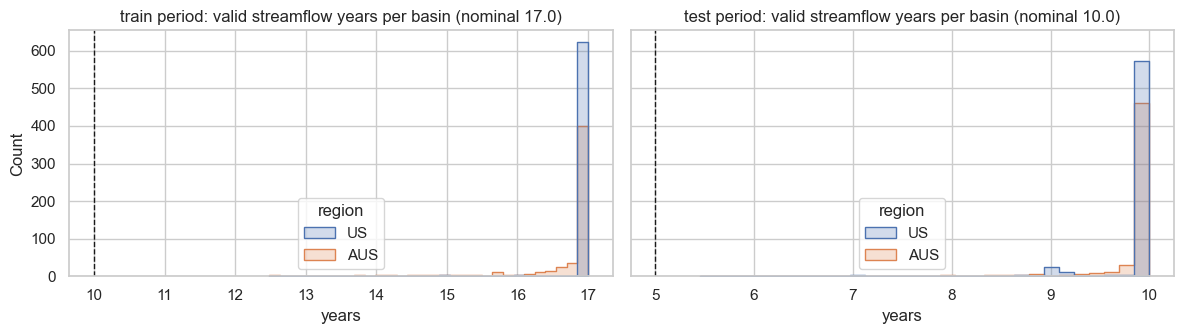

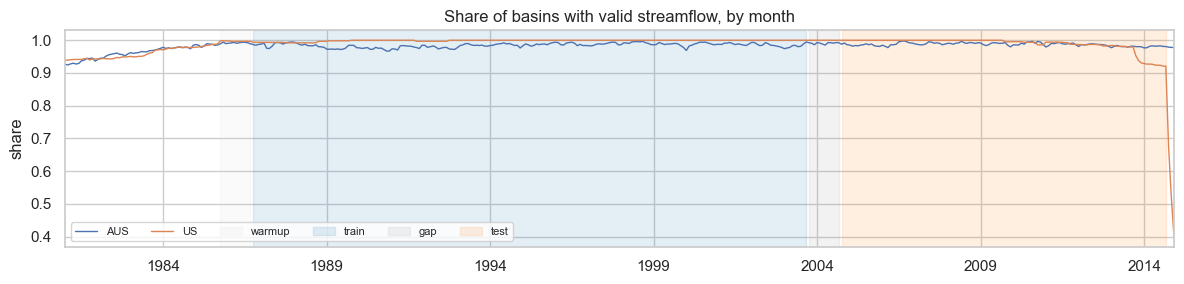

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, period, nmin in zip(axes, ["train", "test"], [MIN_TRAIN_YEARS, MIN_TEST_YEARS]):
    sns.histplot(data=basins, x=f"{period}_valid_years", hue="region", bins=30, ax=ax, element="step")
    ax.axvline(nmin, color="k", ls="--", lw=1)
    ax.set(title=f"{period} period: valid streamflow years per basin (nominal {nominal[period]})", xlabel="years")
plt.tight_layout()

# share of basin-days with valid flow over time, with the period boundaries marked
n_basins = basins["region"].value_counts()
valid_per_day = (
    flow.assign(valid=flow["streamflow"].notna(), region=flow["gauge_id"].map(basins["region"]))
    .groupby(["date", "region"])["valid"].sum().unstack()
)
cover = (valid_per_day / n_basins).resample("MS").mean()  # denominator: all basins in the region
ax = cover.plot(figsize=(12, 3), lw=1)
colors = {"warmup": "0.85", "train": "tab:blue", "gap": "0.6", "test": "tab:orange"}
for name, (a, b) in PERIODS_TS.items():
    ax.axvspan(a, b, color=colors[name], alpha=0.12, label=name)
ax.set(title="Share of basins with valid streamflow, by month", ylabel="share", xlabel="")
ax.legend(ncol=6, fontsize=8, loc="lower left")
plt.tight_layout()

## 3. How far does neighbour information reach?

The worry in the review is that a test basin's near neighbours sit in the training set and hand the model (and the nearest-gauge baseline) information it would not have at a truly ungauged site. To size the spatial blocks, measure how similar two basins' flow is as a function of the distance between them.

For each pair of basins in the same region:
1. take daily log flow, $\log(q + 0.01)$, in the **training period only** (so test years never influence the split),
2. subtract each basin's day-of-year mean, so that two basins aren't "similar" just because both have a wet season,
3. correlate the anomalies (at least 3 years of overlap required).

Most of this similarity comes from shared weather, which the models will see anyway through each basin's own forcing. So this is a conservative (generous) measure of how far neighbour information reaches. It is used only to choose a sensible block size, not as an exact cut-off.

In [6]:
def distance_matrix_km(lat, lon) -> np.ndarray:
    X = np.radians(np.column_stack([lat, lon]))
    return haversine_distances(X) * EARTH_RADIUS_KM


train_start, train_end = PERIODS_TS["train"]
tr_flow = flow[(flow["date"] >= train_start) & (flow["date"] <= train_end)]

pairs = []
for subset in SUBSETS:
    ids = basins.index[basins["subset"] == subset]
    wide = tr_flow[tr_flow["gauge_id"].isin(ids)].pivot(index="date", columns="gauge_id", values="streamflow")[ids]
    logq = np.log(wide + 0.01)
    anom = logq - logq.groupby(logq.index.dayofyear).transform("mean")
    corr = anom.corr(min_periods=3 * 365).to_numpy()
    D = distance_matrix_km(basins.loc[ids, "lat"], basins.loc[ids, "lon"])
    iu = np.triu_indices_from(D, k=1)
    pairs.append(pd.DataFrame({"region": REGION[subset], "dist_km": D[iu], "r": corr[iu]}).dropna())
pairs = pd.concat(pairs, ignore_index=True)

bins = [0, 25, 50, 75, 100, 150, 200, 300, 400, 600, 800, 1200, 2000, 5000]
pairs["dist_bin"] = pd.cut(pairs["dist_km"], bins)
correlogram = pairs.groupby(["region", "dist_bin"], observed=True)["r"].describe()[["count", "25%", "50%", "75%"]]
correlogram.unstack(0)["50%"].round(2)

region,AUS,US
dist_bin,,
"(0, 25]",0.87,0.90
"(25, 50]",0.80,0.85
"(50, 75]",0.75,0.80
"(75, 100]",0.69,0.75
"(100, 150]",0.62,0.69
"(150, 200]",0.55,0.63
"(200, 300]",0.49,0.54
"(300, 400]",0.43,0.45
"(400, 600]",0.35,0.35


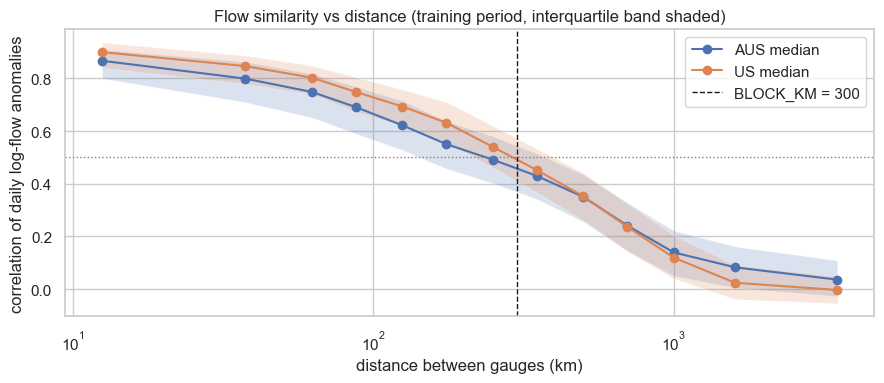

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
for region, g in correlogram.reset_index().groupby("region"):
    mid = g["dist_bin"].apply(lambda iv: (iv.left + iv.right) / 2)
    ax.plot(mid, g["50%"], marker="o", label=f"{region} median")
    ax.fill_between(mid, g["25%"], g["75%"], alpha=0.2)
ax.axvline(BLOCK_KM, color="k", ls="--", lw=1, label=f"BLOCK_KM = {BLOCK_KM}")
ax.axhline(0.5, color="0.5", ls=":", lw=1)
ax.set(xscale="log", xlabel="distance between gauges (km)", ylabel="correlation of daily log-flow anomalies",
       title="Flow similarity vs distance (training period, interquartile band shaded)")
ax.legend()
plt.tight_layout()

**Reading the plot.** Similarity decays smoothly, with no sharp range. Basins within ~25 km are almost interchangeable (r ≈ 0.9), the median correlation crosses 0.5 at roughly 250–400 km, and it reaches about zero only beyond ~1,500 km. Blocking at that scale would leave only a handful of blocks per region, so the default is a compromise: 300 km blocks, plus a buffer that removes the closest training basins (section 5). Try `BLOCK_KM = 500` as a sensitivity check.

## 4. Spatial blocks and folds

**Blocks.** Within each region, complete-linkage agglomerative clustering on great-circle distance, cut at `BLOCK_KM`. Complete linkage guarantees that no two basins in a block are more than `BLOCK_KM` apart, so the blocks stay compact (single linkage would chain along dense coastlines). Regions are blocked separately; they are an ocean apart anyway.

**Folds.** Blocks are assigned to folds region by region, largest first, each to the fold with the fewest basins of that region so far (ties broken at random with `SEED`). Each fold therefore tests roughly 1/`N_FOLDS` of the US basins *and* of the AUS basins.

In [8]:
def spatial_blocks(df: pd.DataFrame, block_km: float) -> pd.Series:
    D = distance_matrix_km(df["lat"], df["lon"])
    labels = AgglomerativeClustering(
        n_clusters=None, metric="precomputed", linkage="complete", distance_threshold=block_km
    ).fit_predict(D)
    return pd.Series(labels, index=df.index)


def assign_folds(df: pd.DataFrame, n_folds: int, seed: int) -> pd.Series:
    rng = np.random.default_rng(seed)
    fold = pd.Series(-1, index=df.index)
    for _, g in df.groupby("subset"):
        sizes = g["block"].value_counts()
        order = sizes.sample(frac=1, random_state=int(rng.integers(1 << 31))).sort_values(ascending=False, kind="stable")
        load = np.zeros(n_folds)
        for block, n in order.items():
            candidates = np.flatnonzero(load == load.min())
            k = int(rng.choice(candidates))
            fold[g.index[g["block"] == block]] = k
            load[k] += n
    return fold


basins["block"] = ""
for subset, g in basins.groupby("subset"):
    lab = spatial_blocks(g, BLOCK_KM)
    basins.loc[g.index, "block"] = [f"{REGION[subset]}-{i:03d}" for i in lab]
basins["fold"] = assign_folds(basins, N_FOLDS, SEED)

block_sizes = basins.groupby(["region", "block"]).size()
print(basins.groupby("region")["block"].nunique().rename("n_blocks").to_string())
print("\nbasins per block:\n", block_sizes.groupby("region").describe()[["min", "50%", "max"]].to_string())
print("\nbasins per fold:")
pd.crosstab(basins["region"], basins["fold"], margins=True)

region
AUS    43
US     87

basins per block:
         min  50%   max
region                
AUS     1.0  6.0  68.0
US      1.0  6.0  27.0

basins per fold:


fold,0,1,2,3,4,All
region,,,,,,
AUS,109,108,108,108,108,541
US,126,126,127,126,126,631
All,235,234,235,234,234,1172


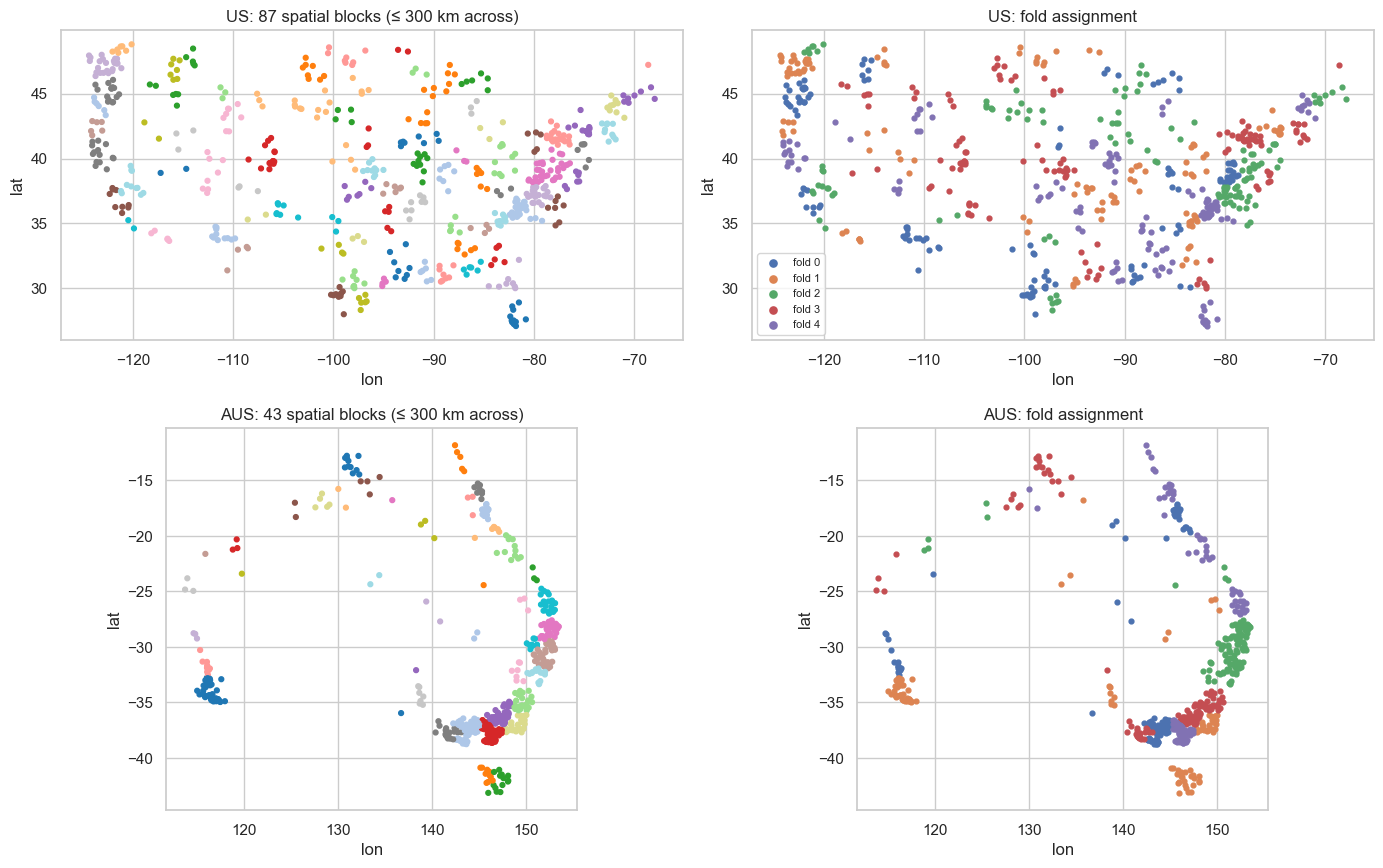

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), gridspec_kw={"height_ratios": [1, 1]})
for row, region in enumerate(["US", "AUS"]):
    g = basins[basins["region"] == region]
    # blocks: cycle a qualitative palette so neighbouring blocks are distinguishable
    codes = g["block"].astype("category").cat.codes
    axes[row, 0].scatter(g["lon"], g["lat"], c=codes % 20, cmap="tab20", s=12)
    axes[row, 0].set(title=f"{region}: {g['block'].nunique()} spatial blocks (≤ {BLOCK_KM} km across)")
    for k in range(N_FOLDS):
        h = g[g["fold"] == k]
        axes[row, 1].scatter(h["lon"], h["lat"], s=12, label=f"fold {k}")
    axes[row, 1].set(title=f"{region}: fold assignment")
    for ax in axes[row]:
        ax.set(xlabel="lon", ylabel="lat")
        ax.set_aspect(1 / np.cos(np.radians(g["lat"].mean())))
axes[0, 1].legend(markerscale=1.5, fontsize=8)
plt.tight_layout()

## 5. Buffer: removing the closest training basins

Blocking keeps a test basin's own block out of training, but the neighbouring block may still be in training, just across the boundary. The buffer handles this: for each fold, any training basin within `BUFFER_KM` of a test basin is set to `buffer` (used neither for training nor testing in that fold).

First, see how many training basins each buffer size would cost.

region,AUS,US
buffer_km,,
0,100.0,100.0
25,99.8,100.0
50,97.7,99.6
100,89.8,93.8
150,79.6,81.3
200,71.9,68.9
300,58.8,47.5


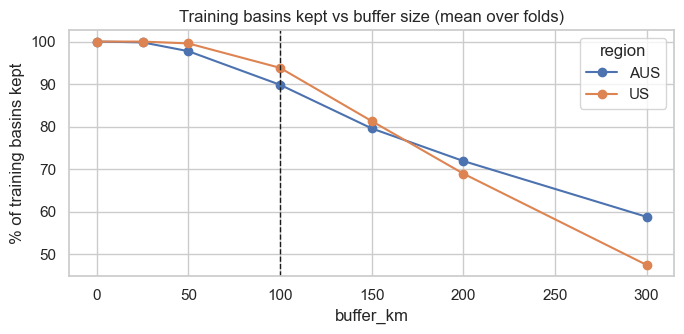

In [10]:
D_all = distance_matrix_km(basins["lat"], basins["lon"])
region_arr = basins["region"].to_numpy()
same_region = region_arr[:, None] == region_arr[None, :]
fold_arr = basins["fold"].to_numpy()

# distance from every basin to the nearest test basin of the same region, per fold
rows = []
for k in range(N_FOLDS):
    is_test = fold_arr == k
    Dk = np.where(same_region[:, is_test], D_all[:, is_test], np.inf)
    rows.append(pd.DataFrame({
        "fold": k,
        "gauge_id": basins.index,
        "region": region_arr,
        "is_test": is_test,
        "dist_to_test_km": np.where(is_test, 0.0, Dk.min(axis=1)),
    }))
roles = pd.concat(rows, ignore_index=True)

buffers = [0, 25, 50, 100, 150, 200, 300]
retention = pd.DataFrame({
    b: roles[~roles["is_test"]].assign(kept=lambda d: d["dist_to_test_km"] >= b).groupby("region")["kept"].mean()
    for b in buffers
}).T.rename_axis("buffer_km")
ax = (100 * retention).plot(marker="o", figsize=(7, 3.5))
ax.axvline(BUFFER_KM, color="k", ls="--", lw=1)
ax.set(ylabel="% of training basins kept", title="Training basins kept vs buffer size (mean over folds)")
plt.tight_layout()
(100 * retention).round(1)

Now compare the three designs on the quantity that matters: **how far is each test basin from its nearest training basin?** Random basin folds (plain `KFold` on basins, which is what the proposal's `GroupKFold` by basin amounts to) are shown for reference.

0.1    0.5    0.9
region design                                      
AUS    blocks + 100 km buffer   116.0  180.0  359.0
       random basin folds         7.0   21.0   69.0
       spatial blocks (300 km)   55.0  132.0  346.0
US     blocks + 100 km buffer   111.0  159.0  254.0
       random basin folds        12.0   38.0  102.0
       spatial blocks (300 km)   75.0  132.0  235.0

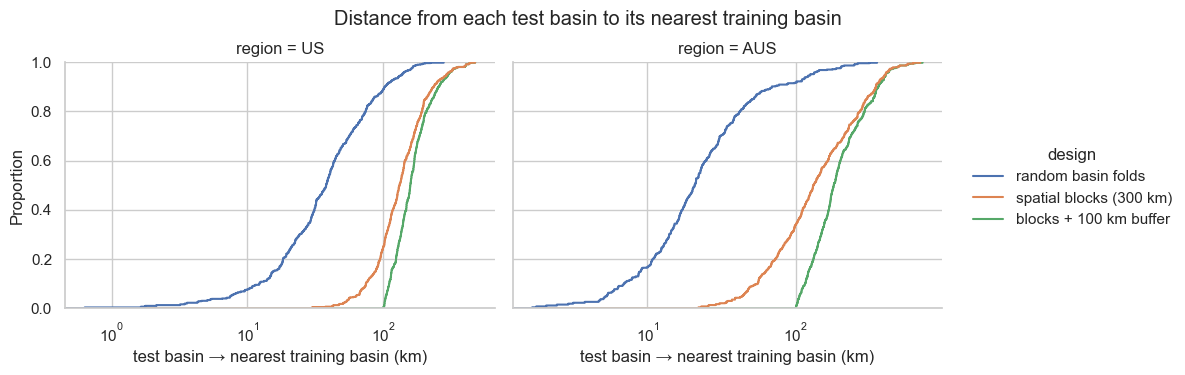

In [11]:
def nearest_train_km(fold_of: np.ndarray, excluded: np.ndarray | None = None) -> np.ndarray:
    # for each basin (as a test basin), distance to the nearest same-region training basin in its fold
    out = np.empty(len(fold_of))
    for i in range(len(fold_of)):
        train = (fold_of != fold_of[i]) & same_region[i]
        if excluded is not None:
            train &= ~excluded[fold_of[i]]
        out[i] = D_all[i, train].min()
    return out


rng = np.random.default_rng(SEED)
random_fold = rng.permutation(np.arange(len(basins)) % N_FOLDS)

buffered = {
    k: ((roles["fold"] == k) & ~roles["is_test"] & (roles["dist_to_test_km"] < BUFFER_KM)).to_numpy()[
        (roles["fold"] == k).to_numpy()
    ]
    for k in range(N_FOLDS)
}
designs = {
    "random basin folds": nearest_train_km(random_fold),
    f"spatial blocks ({BLOCK_KM} km)": nearest_train_km(fold_arr),
    f"blocks + {BUFFER_KM} km buffer": nearest_train_km(fold_arr, buffered),
}
nn = pd.DataFrame(designs, index=basins.index).assign(region=region_arr)
nn_long = nn.melt(id_vars="region", var_name="design", value_name="km")

g = sns.displot(data=nn_long, x="km", hue="design", col="region", kind="ecdf", height=3.5, aspect=1.4,
                facet_kws={"sharex": False})
g.set(xscale="log", xlabel="test basin → nearest training basin (km)")
g.figure.suptitle("Distance from each test basin to its nearest training basin", y=1.04)
nn_long.groupby(["region", "design"])["km"].quantile([0.1, 0.5, 0.9]).unstack().round(0)

With random basin folds, the typical test basin has a training basin a few tens of km away, often a near-twin by the correlogram in section 3. Blocking pushes that distance up, and the buffer sets a hard floor at `BUFFER_KM` for every test basin. The nearest-gauge baseline must use the same donors, so it too will look worse than it would under random folds. That is the honest comparison.

## 6. Write the split tables

`fold_roles.csv` stores `dist_to_test_km` for every training basin, so a downstream script can apply a different buffer (`role = "buffer" if dist_to_test_km < my_buffer`) without rerunning this notebook. The `role` column uses `BUFFER_KM` from above.

In [12]:
roles["role"] = np.where(roles["is_test"], "test", np.where(roles["dist_to_test_km"] < BUFFER_KM, "buffer", "train"))
roles = roles.drop(columns="is_test")
roles["dist_to_test_km"] = roles["dist_to_test_km"].round(1)

SPLITS.mkdir(parents=True, exist_ok=True)
basin_cols = ["region", "subset", "gauge_name", "lat", "lon", "area", "block", "fold",
              "train_valid_years", "test_valid_years", "usable_train", "usable_test"]
basins[basin_cols].to_csv(SPLITS / "basins.csv")
roles.to_csv(SPLITS / "fold_roles.csv", index=False)

config = {
    "subsets": SUBSETS,
    "periods": PERIODS,
    "block_km": BLOCK_KM,
    "n_folds": N_FOLDS,
    "buffer_km": BUFFER_KM,
    "min_train_years": MIN_TRAIN_YEARS,
    "min_test_years": MIN_TEST_YEARS,
    "seed": SEED,
}
(SPLITS / "config.json").write_text(json.dumps(config, indent=2))

for p in sorted(SPLITS.iterdir()):
    print(f"{p.relative_to(REPO)}  ({p.stat().st_size / 1024:.0f} KB)")
pd.crosstab([roles["fold"], roles["region"]], roles["role"])

data\processed\splits\basins.csv  (153 KB)
data\processed\splits\config.json  (0 KB)
data\processed\splits\fold_roles.csv  (198 KB)


role         buffer  test  train
fold region                     
0    AUS         43   109    389
     US          36   126    469
1    AUS         42   108    391
     US          24   126    481
2    AUS          4   108    429
     US          60   127    444
3    AUS         75   108    358
     US          14   126    491
4    AUS         56   108    377
     US          22   126    483

## 7. Using the splits downstream

For fold `k`, a model is fit on the **train-period** days of `train` basins and scored on the **test-period** days of `test` basins. `buffer` basins are ignored in that fold. Everything fit to data (scalers, PCA, clustering, nearest-gauge donors) is fit on that fold's `train` basins only.

The training-basin-count experiment (25/50/100/all) subsamples from a fold's `train` basins; the `test` basins stay fixed so results are comparable across sizes.

The helper below returns the basin ids and date ranges for one fold.

In [13]:
def load_fold(k: int, buffer_km: float | None = None, splits_dir: Path = SPLITS) -> dict:
    # Basin ids and date ranges for fold k; pass buffer_km to override the saved buffer.
    cfg = json.loads((splits_dir / "config.json").read_text())
    info = pd.read_csv(splits_dir / "basins.csv", index_col="gauge_id")
    r = pd.read_csv(splits_dir / "fold_roles.csv").query("fold == @k").set_index("gauge_id")
    if buffer_km is not None:
        r["role"] = np.where(r["role"] == "test", "test", np.where(r["dist_to_test_km"] < buffer_km, "buffer", "train"))
    train = r.index[(r["role"] == "train") & info.loc[r.index, "usable_train"]]
    test = r.index[(r["role"] == "test") & info.loc[r.index, "usable_test"]]
    return {"train_basins": list(train), "test_basins": list(test),
            "train_period": cfg["periods"]["train"], "test_period": cfg["periods"]["test"],
            "warmup_period": cfg["periods"]["warmup"]}


f0 = load_fold(0)
print({k: (f"{len(v)} basins" if k.endswith("basins") else v) for k, v in f0.items()})

{'train_basins': '858 basins', 'test_basins': '235 basins', 'train_period': ['1986-10-01', '2003-09-30'], 'test_period': ['2004-10-01', '2014-09-30'], 'warmup_period': ['1985-10-01', '1986-09-30']}


## Open questions for the team

- **Block size.** 300 km is a judgement call (section 3). A sensitivity run at 500 km would show how much the headline numbers depend on it.
- **Buffer size.** 100 km keeps most training basins (section 5). The buffer could also be swept as its own small experiment: skill vs buffer distance shows directly how much the models lean on neighbours.
- **Nested basins.** Caravan gives gauge points, not catchment polygons, so upstream/downstream pairs can't be identified exactly here. Pairs of nested gauges are usually well within 100 km, so the buffer covers most of them.
- **Climate attributes.** Caravan's climate indices (`p_mean`, `aridity_*`, `frac_snow`, …) are computed over the full record, test years included. Recomputing them from training-period forcing belongs in the attribute-audit step.